# Лабораторная работа 3

Подготовить jupyter-ноутбук с описанием решения. Просьба подробно всё пояснять с комментариями и выводами.

1. Взять стандартную архитектуру ResNet (например, ResNet18 или ResNet34)
2. Обучить ее на выбранном Вами датасете (например, можете взять датасет со спортивными трансляциями). 
Учить с нуля не нужно, достаточно потюнить полносвязный слой.
3. Модифицировать encoder ResNet-а, добавив в него механизм Self-Attention
4. Обучить модифицированную архитектуру с Self-Attention на этом же датасете.
5. Сравнить две модели на тестовой выборке из датасета. Параметры тестирования и сиды необходимо закрепить для проведения корректного сравнения. Составить таблицу с результами. Добавить выводы.

# Решение

### Импорты и фиксация случайности

Подключаем нужные библиотеки и задаём SEED = 42, чтобы запуски были одинаковыми. Это нужно для честного сравнения двух моделей

In [1]:
import os
import random
import time
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

import zipfile

# Фиксируем сиды, чтобы запуски были одинаковыми
SEED = 42

def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seed(SEED)

# Используем GPU, если доступна
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Используем устройство: {device}")

Используем устройство: cuda:0


### Распаковка датасета

Распаковываем архив с Kaggle в папку ./sports. После выполнения внутри будут лежать папки train/, valid/, test/ с подпапками по классам

In [3]:
# Путь к скачанному с Kaggle архиву
zip_path = r"C:\Users\nikgr\Downloads\archive.zip"

# Куда распаковать
extract_to = "./sports"
os.makedirs(extract_to, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_to)

print("Готово, распакован в:", os.path.abspath(extract_to))

Готово, распакован в: c:\Projects\ITMO_ML\laba_08 (03_2_sem)\sports


### Параметры и преобразования картинок

Задаём базовые настройки: размер картинки, размер батча и кол-во воркеров. Картинки нормализуем средними и стд ImageNet — потому что ResNet18 предобучена именно на нём.

Для train добавляем аугментации, чтобы защититься от переобучения. Для valid/test никаких случайностей — тестирование должно быть детерминированным

In [4]:
# Задаем параметры
DATA_DIR = "./sports" 
IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0 


# Статистики ImageNet — на них была предобучена ResNet18, поэтому наши картинки нормализуем теми же числами
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


# Аугментации для train
# Аугментации - искусственное расширение train выборки случайными преобразованиями
# Помогает модели лучше обобщать и не переобучаться
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=25),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


# Преобразования для valid/test
# Тут никакой случайности - нужно детерминированное тестирование
eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


# Загружаем датасеты
train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "train"), transform=train_transform)
valid_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "valid"), transform=eval_transform)
test_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, "test"),  transform=eval_transform)


NUM_CLASSES = len(train_ds.classes)
print(f"Количество классов: {NUM_CLASSES}")
print(f"Train: {len(train_ds)} картинок")
print(f"Valid: {len(valid_ds)} картинок")
print(f"Test:  {len(test_ds)} картинок")
print(f"\nПервые 10 классов: {train_ds.classes[:10]}")

Количество классов: 100
Train: 13492 картинок
Valid: 500 картинок
Test:  500 картинок

Первые 10 классов: ['air hockey', 'ampute football', 'archery', 'arm wrestling', 'axe throwing', 'balance beam', 'barell racing', 'baseball', 'basketball', 'baton twirling']


### Создание DataLoader'ов

Оборачиваем датасеты в DataLoader — он бьёт данные на батчи и (для train) перемешивает

Для train включаем shuffle=True и фиксируем случайность: свой generator для воспроизводимого порядка батчей и worker_init_fn для фиксации сидов внутри воркеров. Это позволит обеим моделям видеть данные в одном и том же порядке

Для valid/test случайности нет, поэтому никаких дополнительных параметров не нужно

In [6]:
import torch, numpy as np, random

# Генератор с фиксированным сидом — для воспроизводимого порядка батчей в train
g = torch.Generator()
g.manual_seed(SEED)

def seed_worker(worker_id):
    """Фиксируем сид внутри каждого воркера DataLoader (нужно при NUM_WORKERS > 0)."""
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, worker_init_fn=seed_worker,
    generator=g
)

valid_loader = DataLoader(
    valid_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)
test_loader  = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS
)

print(f"DataLoader'ы готовы.")
print(f"Батчей в train: {len(train_loader)}, valid: {len(valid_loader)}, test: {len(test_loader)}")

DataLoader'ы готовы.
Батчей в train: 422, valid: 16, test: 16


### Визуальная проверка train-батча

Берём один батч из train_loader, проверяем размерности и отрисовываем 8 картинок с подписями классов

Размерность батча: torch.Size([32, 3, 224, 224])
Размерность меток: torch.Size([32])
Min/Max значений тензора: -2.12 / 2.64


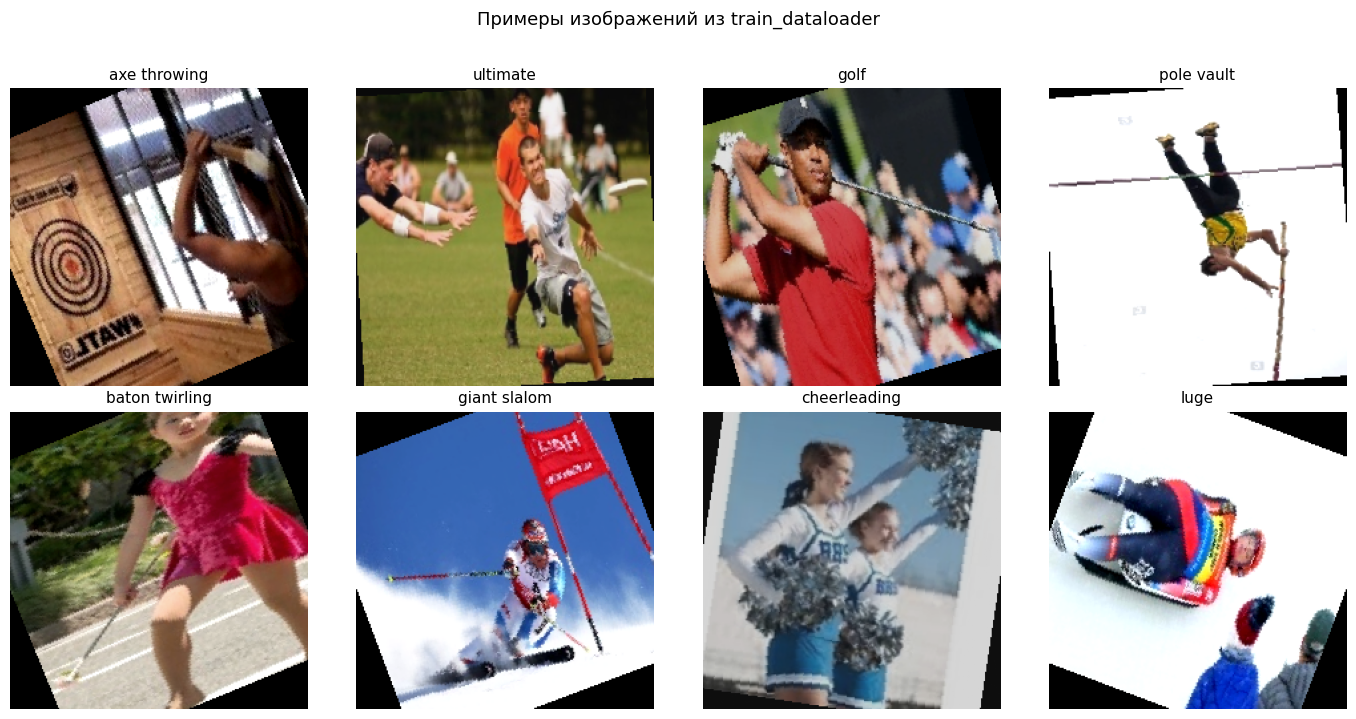

In [7]:
# Берём один батч из train_loader
images, labels = next(iter(train_loader))

print(f"Размерность батча: {images.shape}")
print(f"Размерность меток: {labels.shape}")
print(f"Min/Max значений тензора: {images.min():.2f} / {images.max():.2f}")

# Готовим mean/std для денормализации, чтобы картинки нормально отображались
mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

# Выведем 8 картинок
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    img = images[i] * std + mean
    img = img.permute(1, 2, 0).clamp(0, 1).numpy()
    
    ax.imshow(img)
    ax.set_title(train_ds.classes[labels[i].item()], fontsize=11)
    ax.axis("off")

plt.suptitle("Примеры изображений из train_dataloader", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### Базовая модель — ResNet18

ResNet18 с предобученными весами ImageNet. Т.к. по условию задание "Учить с нуля не нужно, достаточно потюнить полносвязный слой", поэтому encoder заморожен — обучается только полносвязный классификатор

In [ ]:
def build_resnet18_baseline(num_classes):
    # Загружаем ResNet18 с весами, предобученными на ImageNet
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
    # Замораживаем все параметры: градиенты не считаются, веса не обновляются
    for param in model.parameters():
        param.requires_grad = False
    
    # Заменяем последний полносвязный слой:
    # оригинал — Linear(512, 1000) под ImageNet,
    # нам нужен Linear(512, NUM_CLASSES) под наш датасет.
    # Новый слой по умолчанию имеет requires_grad=True — именно он и будет обучаться
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, num_classes)
    
    return model

# Создаём модель и переносим на GPU
model_baseline = build_resnet18_baseline(NUM_CLASSES).to(device)

total_params = sum(p.numel() for p in model_baseline.parameters())
trainable_params = sum(p.numel() for p in model_baseline.parameters() if p.requires_grad)

print(f"Всего параметров:      {total_params:,}")
print(f"Обучаемых параметров:  {trainable_params:,}")
print(f"Доля обучаемых:        {100*trainable_params/total_params:.4f}%")

Всего параметров:      11,227,812
Обучаемых параметров:  51,300
Доля обучаемых:        0.4569%


Выводим список параметров, у которых requires_grad=True. Должны быть только fc.weight и fc.bias — значит, заморозка encoder сработала, и обучаться будет только полносвязный слой

In [16]:
print("Обучаемые слои:")
for name, param in model_baseline.named_parameters():
    if param.requires_grad:
        print(f"  {name}: shape={tuple(param.shape)}")

Обучаемые слои:
  fc.weight: shape=(100, 512)
  fc.bias: shape=(100,)


Тестово прогоним один батч, чтобы убедиться, что модель в принципе работает с нашими данными

In [9]:
images, labels = next(iter(train_loader))
images = images.to(device)

model_baseline.eval()
with torch.no_grad():
    outputs = model_baseline(images)

print(f"Вход:  {images.shape}")
print(f"Выход: {outputs.shape}")
print(f"Пример логитов первой картинки (первые 5): {outputs[0][:5]}")

Вход:  torch.Size([32, 3, 224, 224])
Выход: torch.Size([32, 100])
Пример логитов первой картинки (первые 5): tensor([ 0.8076,  0.4888, -0.4973,  0.1087,  0.6409], device='cuda:0')


### Self-Attention модуль (CBAM)

Реализуем механизм Self-Attention для свёрточной сети — CBAM (Convolutional Block Attention Module)

Модуль состоит из двух частей:
1. ChannelAttention — отвечает на вопрос «какие каналы важны». Смотрит на усреднённый и максимальный «портрет» каждого канала, прогоняет через общий MLP и через sigmoid получает веса
2. SpatialAttention — отвечает на вопрос «где на картинке важно». Усредняет и максимизирует по каналам, склеивает, через свёртку 7×7 получает карту внимания

Оба модуля не меняют размер тензора, только перевзвешивают значения. CBAM собирает их последовательно: сначала каналы, потом пространство.

In [10]:
class ChannelAttention(nn.Module):
    def __init__(self, in_channels: int, reduction: int = 16):
        
        super().__init__()

        # max(..., 8) — чтобы не получить 0 при малом числе каналов
        hidden = max(in_channels // reduction, 8)
        
        # Глобальный pooling
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        
        # Общий MLP для avg и max веток.
        self.mlp = nn.Sequential(
            nn.Conv2d(in_channels, hidden, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, in_channels, kernel_size=1, bias=False),
        )
        
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        avg_out = self.mlp(self.avg_pool(x)) 
        max_out = self.mlp(self.max_pool(x)) 
        attn = self.sigmoid(avg_out + max_out) 
        return x * attn 


class SpatialAttention(nn.Module):

    def __init__(self, kernel_size: int = 7):
        super().__init__()
        padding = kernel_size // 2  
        # Вход: 2 канала (avg+max по каналам). Выход: 1 канал — карта внимания
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        # Pooling по каналам (dim=1)
        avg_out = torch.mean(x, dim=1, keepdim=True) 
        max_out, _ = torch.max(x, dim=1, keepdim=True) 
        # max возвращает (values, indices), берём только значения
        
        concat = torch.cat([avg_out, max_out], dim=1)  
        attn = self.sigmoid(self.conv(concat)) 
        return x * attn


class CBAM(nn.Module):

    def __init__(self, in_channels: int, reduction: int = 16, spatial_kernel: int = 7):
        super().__init__()
        self.channel_attn = ChannelAttention(in_channels, reduction)
        self.spatial_attn = SpatialAttention(spatial_kernel)
    
    def forward(self, x):
        x = self.channel_attn(x)
        x = self.spatial_attn(x)
        return x

### Проверка CBAM-модуля

Создаём CBAM на 64 канала и прогоняем через него случайный тензор. Главное — убедиться, что размер тензора не меняется: вход и выход одинаковые. Это значит, что CBAM можно вставить между слоями ResNet, ничего не ломая

Заодно смотрим, сколько параметров добавляет модуль 

In [11]:
# Тестовый вход: как будто выход layer1 ResNet18 — 64 канала, 56×56
test_input = torch.randn(2, 64, 56, 56).to(device)

# Создаём CBAM на 64 канала
cbam = CBAM(in_channels=64).to(device)

# Прогоняем
test_output = cbam(test_input)

print(f"Вход:  {test_input.shape}")
print(f"Выход: {test_output.shape}")
print(f"Размер не изменился: {test_input.shape == test_output.shape}")

# Параметры CBAM
params = sum(p.numel() for p in cbam.parameters())
print(f"\nПараметров в CBAM(64): {params}")
print(f"ChannelAttention: {sum(p.numel() for p in cbam.channel_attn.parameters())}")
print(f"SpatialAttention: {sum(p.numel() for p in cbam.spatial_attn.parameters())}")

Вход:  torch.Size([2, 64, 56, 56])
Выход: torch.Size([2, 64, 56, 56])
Размер не изменился: True

Параметров в CBAM(64): 1122
ChannelAttention: 1024
SpatialAttention: 98


### ResNet18 + Self-Attention

Теперь интегрируем CBAM в архитектуру ResNet18. Загружаем pretrained-ResNet18, разбираем её по частям, чтобы получить доступ к каждому layer, и вставляем CBAM блок после каждого из четырёх этапов. Завершающие avgpool и fc оставляем как обычно

Encoder замораживаем, обучаться будут только CBAM модули и fc

In [13]:
class ResNet18WithAttention(nn.Module):
    
    def __init__(self, num_classes: int, pretrained: bool = True, freeze_backbone: bool = True):
        super().__init__()
        
        # Загружаем готовую ResNet18 с весами ImageNet
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        
        # Разбираем модель по частям — чтобы вставлять CBAM МЕЖДУ слоями
        self.stem = nn.Sequential(
            backbone.conv1,
            backbone.bn1,
            backbone.relu,
            backbone.maxpool,
        )
        self.layer1 = backbone.layer1   # выход:  64 канала
        self.layer2 = backbone.layer2   # выход: 128 каналов
        self.layer3 = backbone.layer3   # выход: 256 каналов
        self.layer4 = backbone.layer4   # выход: 512 каналов
        
        # CBAM после каждого layer.
        self.attn1 = CBAM(64)
        self.attn2 = CBAM(128)
        self.attn3 = CBAM(256)
        self.attn4 = CBAM(512)
        
        # Финальные слои как в оригинальной ResNet18
        self.avgpool = backbone.avgpool
        self.fc = nn.Linear(512, num_classes)
        
        # Замораживаем оригинальный encoder, CBAM и fc остаются обучаемыми
        if freeze_backbone:
            for module in [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]:
                for p in module.parameters():
                    p.requires_grad = False
    
    def forward(self, x):
        x = self.stem(x)
        x = self.attn1(self.layer1(x))
        x = self.attn2(self.layer2(x))
        x = self.attn3(self.layer3(x))
        x = self.attn4(self.layer4(x))
        x = self.avgpool(x)
        x = torch.flatten(x, 1) 
        x = self.fc(x)
        return x

# Создаём модель и переносим на GPU
model_attn = ResNet18WithAttention(NUM_CLASSES).to(device)

# Проверка количества параметров
total = sum(p.numel() for p in model_attn.parameters())
trainable = sum(p.numel() for p in model_attn.parameters() if p.requires_grad)
print(f"Всего параметров:      {total:,}")
print(f"Обучаемых параметров:  {trainable:,}")
print(f"Доля обучаемых:        {100*trainable/total:.2f}%")

Всего параметров:      11,272,236
Обучаемых параметров:  95,724
Доля обучаемых:        0.85%


### Проверка модели с Self-Attention

In [14]:
# Прогоняем один батч через модель с attention
images, labels = next(iter(train_loader))
images = images.to(device)

model_attn.eval()
with torch.no_grad():
    outputs = model_attn(images)

print(f"Вход:  {images.shape}")
print(f"Выход: {outputs.shape}")
print(f"Пример логитов: {outputs[0][:5]}")

Вход:  torch.Size([32, 3, 224, 224])
Выход: torch.Size([32, 100])
Пример логитов: tensor([-0.0050,  0.5763, -0.1170,  0.2735, -0.0843], device='cuda:0')


### Универсальная функция обучения

Одна функция для обучения обеих моделей. На каждом запуске сбрасываем сиды, чтобы и baseline, и attention-модель стартовали из одинакового состояния. 

По ходу обучения ведём историю метрик и сохраняем веса с лучшей val_acc

In [16]:
def train_model(model: nn.Module,
                train_loader,
                valid_loader,
                num_epochs: int = 10,
                lr: float = 1e-3,
                seed: int = SEED,
                model_name: str = "model"):
    
    # Сброс сидов перед каждой моделью
    set_seed(seed)
    
    # Функция потерь
    criterion = nn.CrossEntropyLoss()
    
    # Оптимизатор. Обучает только параметры с requires_grad=True
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)
    
    # Scheduler плавно уменьшает lr по косинусу к концу обучения
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    
    # История метрик по эпохам
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    
    # Лучшие веса
    best_val_acc = 0.0
    best_state = copy.deepcopy(model.state_dict())
    
    print(f"\n{'='*60}")
    print(f"Обучение модели: {model_name}")
    print(f"{'='*60}")
    
    for epoch in range(num_epochs):
        # TRAIN 
        model.train()
        
        running_loss = 0.0
        correct = 0
        total = 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            # Стандартный шаг обучения:
            optimizer.zero_grad()              # обнуляем градиенты с прошлого шага
            outputs = model(images)            # forward
            loss = criterion(outputs, labels)  # считаем потерю
            loss.backward()                    # backward: считаем градиенты
            optimizer.step()                   # обновляем веса
            
            # Метрики
            running_loss += loss.item() * images.size(0)
            _, preds = outputs.max(1) 
            correct += preds.eq(labels).sum().item()
            total += labels.size(0)
        
        train_loss = running_loss / total
        train_acc = correct / total
        
        # VALIDATION
        model.eval()
        
        v_loss = 0.0
        v_correct = 0
        v_total = 0
        
        with torch.no_grad():
            for images, labels in valid_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                v_loss += loss.item() * images.size(0)
                _, preds = outputs.max(1)
                v_correct += preds.eq(labels).sum().item()
                v_total += labels.size(0)
        
        val_loss = v_loss / v_total
        val_acc = v_correct / v_total
        
        # Уменьшаем lr на следующую эпоху
        scheduler.step()
        
        # Записываем историю
        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        
        # Сохраняем веса, если эпоха дала лучшую val_acc
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = copy.deepcopy(model.state_dict())
            marker = " ← best"
        else:
            marker = ""
        
        print(f"Epoch {epoch+1:2d}/{num_epochs} | "
              f"train: loss={train_loss:.4f} acc={train_acc:.4f} | "
              f"val: loss={val_loss:.4f} acc={val_acc:.4f}{marker}")
    
    # Возвращаем модель с лучшими весами, а не с последними
    model.load_state_dict(best_state)
    
    return {
        "model": model,
        "history": history,
        "best_val_acc": best_val_acc,
    }

### Обучение обеих моделей

In [17]:
# Гиперпараметры 
NUM_EPOCHS = 10
LR = 1e-3

# Baseline ResNet18: учится только полносвязный слой
result_baseline = train_model(
    model_baseline,
    train_loader,
    valid_loader,
    num_epochs=NUM_EPOCHS,
    lr=LR,
    seed=SEED,
    model_name="ResNet18 (baseline)",
)

# ResNet18 + Self-Attention: учатся CBAM-блоки и fc
result_attn = train_model(
    model_attn,
    train_loader,
    valid_loader,
    num_epochs=NUM_EPOCHS,
    lr=LR,
    seed=SEED,
    model_name="ResNet18 + Self-Attention (CBAM)",
)


Обучение модели: ResNet18 (baseline)
Epoch  1/10 | train: loss=2.8620 acc=0.3878 | val: loss=1.3276 acc=0.7000 ← best
Epoch  2/10 | train: loss=1.5218 acc=0.6479 | val: loss=0.8730 acc=0.7780 ← best
Epoch  3/10 | train: loss=1.1835 acc=0.7113 | val: loss=0.6885 acc=0.8240 ← best
Epoch  4/10 | train: loss=1.0230 acc=0.7407 | val: loss=0.6713 acc=0.8020
Epoch  5/10 | train: loss=0.9308 acc=0.7606 | val: loss=0.5891 acc=0.8420 ← best
Epoch  6/10 | train: loss=0.8667 acc=0.7733 | val: loss=0.5841 acc=0.8240
Epoch  7/10 | train: loss=0.8171 acc=0.7893 | val: loss=0.5856 acc=0.8300
Epoch  8/10 | train: loss=0.7840 acc=0.8014 | val: loss=0.5329 acc=0.8460 ← best
Epoch  9/10 | train: loss=0.7644 acc=0.8059 | val: loss=0.5194 acc=0.8560 ← best
Epoch 10/10 | train: loss=0.7497 acc=0.8106 | val: loss=0.5342 acc=0.8500

Обучение модели: ResNet18 + Self-Attention (CBAM)
Epoch  1/10 | train: loss=3.0081 acc=0.3501 | val: loss=1.3981 acc=0.6840 ← best
Epoch  2/10 | train: loss=1.3756 acc=0.6657 | va

### Оценка моделей на тестовой выборке

Прогоняем обученные модели через test_loader и считаем метрики:

Top-1 Accuracy — доля точно угаданных классов

Top-5 Accuracy — попал ли правильный класс в пятёрку самых вероятных

Loss — средняя кросс-энтропия

Inference time — время прогона теста

**Время на GPU измеряется с прогревом и torch.cuda.synchronize(). GPU работает асинхронно, и без этих штук замер был бы неточным. В конце сразу считаем overhead — на сколько процентов медленнее attention-модель**

In [23]:
@torch.no_grad()
def evaluate(model: nn.Module,
             loader,
             criterion: nn.Module = nn.CrossEntropyLoss(),
             measure_time: bool = True) -> dict:
    
    # Сбрасываем сиды для воспроизводимости теста
    set_seed(SEED)
    
    model.eval()
    
    # Прогрев GPU — один холостой батч
    if measure_time and device.type == "cuda":
        for images, _ in loader:
            _ = model(images.to(device))
            break
    
    total_loss = 0.0
    total = 0
    correct_top1 = 0
    correct_top5 = 0
    all_labels = []
    all_preds = []
    
    # GPU работает асинхронно: операции «ставятся в очередь», а не выполняются мгновенно
    # synchronize() дожидается завершения всех операций перед стартом таймера
    if measure_time and device.type == "cuda":
        torch.cuda.synchronize()
    start_time = time.time()
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        outputs = model(images)
        loss = criterion(outputs, labels)
        total_loss += loss.item() * images.size(0)
        
        # Top-1 класс с максимальным логитом
        _, preds_top1 = outputs.max(1)
        correct_top1 += preds_top1.eq(labels).sum().item()
        
        # Top-5 правильный класс попал в пятёрку самых вероятных
        _, preds_top5 = outputs.topk(5, dim=1)
        correct_top5 += preds_top5.eq(labels.unsqueeze(1)).any(dim=1).sum().item()
        
        total += labels.size(0)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds_top1.cpu().numpy())
    
    # Снова дожидаемся всех GPU-операций перед остановкой таймера
    if measure_time and device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.time() - start_time
    
    return {
        "loss": total_loss / total,
        "top1_acc": correct_top1 / total,
        "top5_acc": correct_top5 / total,
        "inference_time_sec": elapsed,
        "samples": total,
        "labels": np.array(all_labels),
        "preds": np.array(all_preds),
    }


# Запускаем тестирование обеих моделей
print("Тестирование baseline...")
eval_baseline = evaluate(result_baseline["model"], test_loader)

print("Тестирование attention-модели...")
eval_attn = evaluate(result_attn["model"], test_loader)

print(f"\n{'='*65}")
print(f"{'Метрика':<28}{'Baseline':>15}{'+ Self-Attention':>22}")
print(f"{'='*65}")
print(f"{'Top-1 Accuracy':<28}{eval_baseline['top1_acc']:>15.4f}{eval_attn['top1_acc']:>22.4f}")
print(f"{'Top-5 Accuracy':<28}{eval_baseline['top5_acc']:>15.4f}{eval_attn['top5_acc']:>22.4f}")
print(f"{'Loss (CrossEntropy)':<28}{eval_baseline['loss']:>15.4f}{eval_attn['loss']:>22.4f}")
print(f"{'Inference time, sec':<28}{eval_baseline['inference_time_sec']:>15.2f}{eval_attn['inference_time_sec']:>22.2f}")

Тестирование baseline...
Тестирование attention-модели...

Метрика                            Baseline      + Self-Attention
Top-1 Accuracy                       0.8580                0.8700
Top-5 Accuracy                       0.9800                0.9840
Loss (CrossEntropy)                  0.4513                0.4871
Inference time, sec                    0.72                  0.67


### Итоговая таблица сравнения

Собираем все ключевые метрики обеих моделей в единую таблицу

In [26]:
def count_params(model: nn.Module) -> tuple[int, int]:
    """Возвращает (всего параметров, обучаемых параметров)."""
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# Параметры для обеих моделей
total_baseline, trainable_baseline = count_params(result_baseline["model"])
total_attn,     trainable_attn     = count_params(result_attn["model"])

# Итоговая таблица для отчёта
summary = pd.DataFrame({
    "Метрика": [
        "Test Top-1 Accuracy",
        "Test Top-5 Accuracy",
        "Test Loss (CrossEntropy)",
        "Best Valid Top-1 Accuracy",
        "Final Train Accuracy",
        "Параметры всего",
        "Параметры обучаемые",
        "Доля обучаемых, %",
        "Inference time, сек",
        "Inference time на 1 картинку, мс",
    ],
    "ResNet18 (baseline)": [
        f"{eval_baseline['top1_acc']:.4f}",
        f"{eval_baseline['top5_acc']:.4f}",
        f"{eval_baseline['loss']:.4f}",
        f"{result_baseline['best_val_acc']:.4f}",
        f"{result_baseline['history']['train_acc'][-1]:.4f}",
        f"{total_baseline:,}",
        f"{trainable_baseline:,}",
        f"{100 * trainable_baseline / total_baseline:.3f}",
        f"{eval_baseline['inference_time_sec']:.2f}",
        f"{eval_baseline['inference_time_sec'] / eval_baseline['samples'] * 1000:.2f}",
    ],
    "ResNet18 + Self-Attention": [
        f"{eval_attn['top1_acc']:.4f}",
        f"{eval_attn['top5_acc']:.4f}",
        f"{eval_attn['loss']:.4f}",
        f"{result_attn['best_val_acc']:.4f}",
        f"{result_attn['history']['train_acc'][-1]:.4f}",
        f"{total_attn:,}",
        f"{trainable_attn:,}",
        f"{100 * trainable_attn / total_attn:.3f}",
        f"{eval_attn['inference_time_sec']:.2f}",
        f"{eval_attn['inference_time_sec'] / eval_attn['samples'] * 1000:.2f}",
    ],
})

print(summary.to_string(index=False))

                         Метрика ResNet18 (baseline) ResNet18 + Self-Attention
             Test Top-1 Accuracy              0.8580                    0.8700
             Test Top-5 Accuracy              0.9800                    0.9840
        Test Loss (CrossEntropy)              0.4513                    0.4871
       Best Valid Top-1 Accuracy              0.8560                    0.8400
            Final Train Accuracy              0.8106                    0.8377
                 Параметры всего          11,227,812                11,272,236
             Параметры обучаемые              51,300                    95,724
               Доля обучаемых, %               0.457                     0.849
             Inference time, сек                0.72                      0.67
Inference time на 1 картинку, мс                1.44                      1.34


### Графики обучения

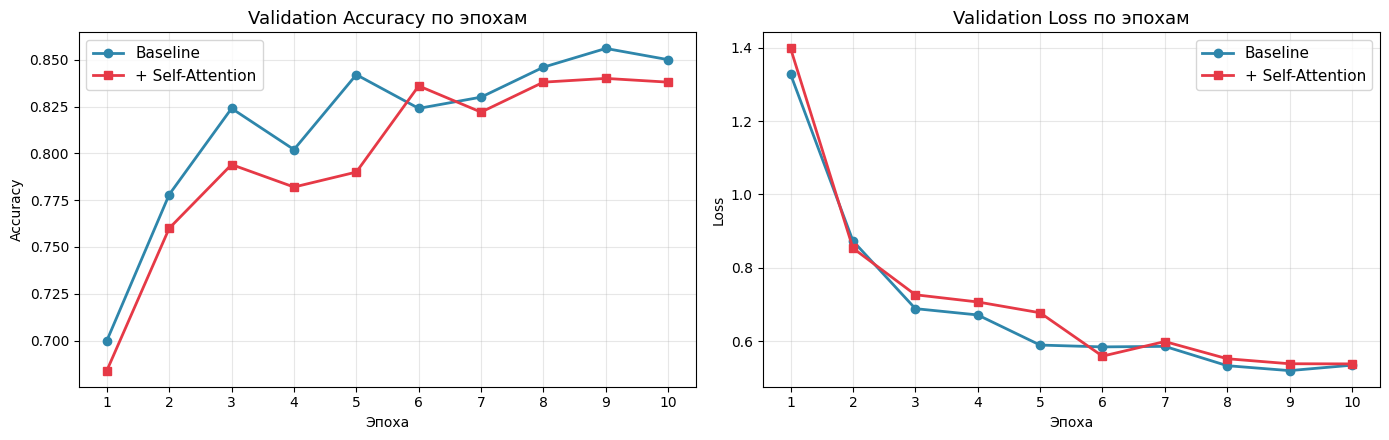

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

epochs = range(1, NUM_EPOCHS + 1)

# График 1: Validation Accuracy
axes[0].plot(epochs, result_baseline["history"]["val_acc"],
             label="Baseline", marker="o", linewidth=2, color="#2E86AB")
axes[0].plot(epochs, result_attn["history"]["val_acc"],
             label="+ Self-Attention", marker="s", linewidth=2, color="#E63946")
axes[0].set_title("Validation Accuracy по эпохам", fontsize=13)
axes[0].set_xlabel("Эпоха")
axes[0].set_ylabel("Accuracy")
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=11)
axes[0].set_xticks(epochs)

# График 2: Validation Loss
axes[1].plot(epochs, result_baseline["history"]["val_loss"],
             label="Baseline", marker="o", linewidth=2, color="#2E86AB")
axes[1].plot(epochs, result_attn["history"]["val_loss"],
             label="+ Self-Attention", marker="s", linewidth=2, color="#E63946")
axes[1].set_title("Validation Loss по эпохам", fontsize=13)
axes[1].set_xlabel("Эпоха")
axes[1].set_ylabel("Loss")
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=11)
axes[1].set_xticks(epochs)

plt.tight_layout()
plt.show()

### Вывод

В ходе лабораторной работы была изучена и применена техника transfer learning на основе стандартной архитектуры ResNet18, а также реализована её модификация с механизмом Self-Attention.

В качестве датасета использовался Sports Image Classification. На первом этапе была построена базовая модель, предобученная на ImageNet ResNet18 с замороженным encoder и обучаемым полносвязным слоем. Такой подход позволил обучить всего около 51 тысячи параметров (менее 0.5% от общего числа) и достичь Top-1 accuracy 85.8% на тестовой выборке, что подтверждает эффективность переноса знаний из ImageNet на близкие задачи классификации изображений.

На втором этапе encoder ResNet18 был модифицирован путём добавления механизма Self-Attention в виде CBAM-блоков после каждой стадии. Общее число обучаемых параметров выросло до примерно 96 тысяч, что по-прежнему составляет менее 1% от полной сети.

Сравнение двух моделей проводилось в строго одинаковых условиях: с фиксированным сидом, сбрасываемым перед обучением каждой модели, с идентичными гиперпараметрами, одинаковыми DataLoader'ами и аугментациями. Тестирование выполнялось без shuffle и без аугментаций, время инференса измерялось с прогревом GPU и torch.cuda.synchronize() для корректного замера.

Результаты на тестовой выборке показали, что модель с Self-Attention превзошла baseline по точности: Top-1 accuracy выросла с 85.8% до 87.0% (+1.2 п.п.), Top-5 accuracy — с 98.0% до 98.4%. При этом Test Loss у attention-модели оказался немного выше (0.4871 против 0.4513), что говорит о том, что модель чаще даёт правильное предсказание, но с меньшей уверенностью в нём. Время инференса у обеих моделей сопоставимо (0.67 и 0.72 секунды соответственно), разница в пределах погрешности измерения на тестовой выборке из 500 картинок